In [314]:
%load_ext autoreload
%autoreload 2


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Evaluation & Visualization

**Sections:**
- **A — Setup:** load checkpoints, dataset, pred cache
- **B — Qualitative refinement:** add noise to GT keypoints, refine, compare across settings
- **C — Critical failure cases:** joint swapping, large corruption — does the model recover?
- **D — Quantitative results:** arch-ablation and inference-ablation tables + plots


## A — Setup


In [315]:

from pathlib import Path
import json

import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import numpy as np
import pandas as pd
import torch
import torchvision

from src.data import PoseDataset, CROWDPOSE_EDGE_LIST, CROWDPOSE_JOINT_NAMES, read_image_size
from src.vis import show_img_with_keypoints
from scripts.benchmark_diffusion_refiner import load_module

# Paths
CKPT_MP   = Path("results/sweeps/arch-message-passing/task_1/20260316_003813/checkpoints/epoch140-running_loss_5=0.0155.ckpt")
CKPT_NOMP = Path("results/sweeps/arch-message-passing/task_2/20260316_032147/checkpoints/epoch116-running_loss_5=0.0350.ckpt")
PRED_CACHE = "results/cache/rtmpose-m_crowdpose_val_predictions.pkl"
ANN_FILE   = "data/crowdpose/annotations/crowdpose_val.json"
IMG_ROOT   = Path("data/crowdpose/images")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {DEVICE}")


Device: cuda


In [316]:
# Load both checkpoints
# module_mp  : w/ message passing  (main model)
# module_nomp: w/o message passing

def _load(ckpt_path: Path) -> "PoseDiffusionModule":
    run_dir = ckpt_path.parent.parent
    return load_module(
        checkpoint_path=ckpt_path,
        run_dir=run_dir,
        pred_cache=PRED_CACHE,
        ann_file=ANN_FILE,
        dino_cache_override=None,
        batch_size=64,
        device=DEVICE,
    )

module_mp   = _load(CKPT_MP)
module_nomp = _load(CKPT_NOMP)
print("Loaded w/ MP  :", CKPT_MP.name)
print("Loaded wo/ MP :", CKPT_NOMP.name)


loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
loading annotations into memory...
Done (t=0.06s)
creating index...
index created!
DinoConditioner: registered 3 cache dir(s)
loading annotations into memory...
Done (t=0.05s)
creating index...
index created!
loading annotations into memory...
Done (t=0.36s)
creating index...
index created!
DinoConditioner: registered 3 cache dir(s)
Loaded w/ MP  : epoch140-running_loss_5=0.0155.ckpt
Loaded wo/ MP : epoch116-running_loss_5=0.0350.ckpt


In [339]:
module_mp

PoseDiffusionModule(
  (model): KeypointDiffusionModel(
    (position_embedding): Sequential(
      (0): Linear(in_features=2, out_features=256, bias=True)
      (1): GELU(approximate='none')
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=256, out_features=256, bias=True)
    )
    (node_idx_embedding): Embedding(14, 256)
    (node_init_norm): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (timestep_embedding): TimestepSinusoidalEmbedding()
    (global_cond_mlp): Sequential(
      (0): Linear(in_features=256, out_features=128, bias=True)
      (1): GELU(approximate='none')
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=128, out_features=128, bias=True)
    )
    (edge_encoder): Sequential(
      (0): Linear(in_features=2, out_features=64, bias=True)
      (1): GELU(approximate='none')
      (2): Dropout(p=0.1, inplace=False)
      (3): Linear(in_features=64, out_features=64, bias=True)
    )
    (decoder): PoseGraphDecoder(
   

In [317]:
# Val dataset
val_dataset = PoseDataset.from_path(ANN_FILE, img_root=IMG_ROOT)
print(f"Val dataset: {len(val_dataset)} images")


Val dataset: 2000 images


## B — Qualitative Refinement

Show ground-truth keypoints, add Gaussian noise to wrist joints, then refine with the model.

Comparisons:
- +DM with diffusion steps ∈ [1, 2, 3]  (w/ Message Passing)
- +DM vs −DM (single-pass)  ×  w/ MP vs w/o MP


In [318]:

J          = CROWDPOSE_JOINT_NAMES
STEPS      = 1
NOISE_FRAC = 0.2
NOISE_STD  = 60.0

N_STEPS_LIST     = [1, 2, 3]
FAIL_STEPS_LIST  = [1, 2, 3]
FAIL_PASSES_LIST = [1, 2, 3, 5]

SAMPLE_IDX     = 7
SAMPLE_INDICES = [7, 0, 1]

LAYER_STYLES = {
    "gt":     ("--", 0.85),
    "pred":   ("-",  0.85),
    "gt_ref": ("--", 0.8),
}

PERSON_COLORS = ["#e41a1c", "#377eb8", "#ff7f00", "#984ea3", "#4daf4a", "#a65628", "#f781bf", "#aaaaaa"]

EVAL_DIR = Path("results/evaluation")
(EVAL_DIR / "figures").mkdir(parents=True, exist_ok=True)
(EVAL_DIR / "tables").mkdir(parents=True, exist_ok=True)

sample     = val_dataset[SAMPLE_IDX]
gt_kpts    = sample["keypoints"]
vis        = sample["visibility"]
img_tensor = torchvision.io.read_image(sample["img_path"])
img_np     = img_tensor.permute(1, 2, 0).numpy()


In [319]:

def draw_pose(ax, keypoints_px, visibility=None, *, linestyle="-", alpha=0.85, lw=1.5, ms=4):
    """Overlay per-person skeleton + joints on ax.

    Visibility: 2=filled circle, 1=open circle, 0=cross (omitted from skeleton).
    Pass visibility=None to treat all joints as visible.
    """
    kpts = np.asarray(keypoints_px.numpy() if isinstance(keypoints_px, torch.Tensor) else keypoints_px)
    vis_ = (np.asarray(visibility.numpy() if isinstance(visibility, torch.Tensor) else visibility)
            if visibility is not None else None)

    for p in range(len(kpts)):
        color = PERSON_COLORS[p % len(PERSON_COLORS)]
        vis_p = vis_[p] if vis_ is not None else None

        for u, v in CROWDPOSE_EDGE_LIST:
            if vis_p is not None and (vis_p[u] == 0 or vis_p[v] == 0):
                continue
            ax.plot([kpts[p, u, 0], kpts[p, v, 0]],
                    [kpts[p, u, 1], kpts[p, v, 1]],
                    color=color, linestyle=linestyle, alpha=alpha, linewidth=lw, zorder=2)

        if vis_p is None:
            ax.plot(kpts[p, :, 0], kpts[p, :, 1],
                    "o", color=color, markersize=ms, alpha=alpha, zorder=3)
        else:
            vis_idx  = np.where(vis_p == 2)[0]
            occl_idx = np.where(vis_p == 1)[0]
            abs_idx  = np.where(vis_p == 0)[0]
            if len(vis_idx):
                ax.plot(kpts[p, vis_idx, 0], kpts[p, vis_idx, 1],
                        "o", color=color, markersize=ms, alpha=alpha, zorder=3)
            if len(occl_idx):
                ax.plot(kpts[p, occl_idx, 0], kpts[p, occl_idx, 1],
                        "o", color=color, markersize=ms, alpha=alpha,
                        markerfacecolor="none", zorder=3)
            if len(abs_idx):
                ax.plot(kpts[p, abs_idx, 0], kpts[p, abs_idx, 1],
                        "x", color=color, markersize=ms, alpha=alpha, zorder=3)


def _pose_legend(fig):
    handles = [
        mlines.Line2D([], [], color="gray", linestyle="--", linewidth=1.5, label="Ground Truth"),
        mlines.Line2D([], [], color="gray", linestyle="-",  linewidth=1.5, label="Prediction"),
        mlines.Line2D([], [], color="gray", marker="o", linestyle="none", markersize=6, label="visible"),
        mlines.Line2D([], [], color="gray", marker="o", linestyle="none", markersize=6,
                      markerfacecolor="none", label="occluded"),
        mlines.Line2D([], [], color="gray", marker="x", linestyle="none", markersize=6, label="absent"),
    ]
    fig.legend(handles=handles, loc="lower center", ncol=5, fontsize=8, frameon=True,
               bbox_to_anchor=(0.5, -0.04))


def comparison_figure(
    img_np_list,
    panels_list,
    col_titles,
    suptitle="",
    row_titles=None,
    col_width=3.2,
    row_height=3.5,
    save_path=None,
):
    """Draw a rows x cols grid of pose overlays.

    panels_list[row][col] = [(kpts, vis_or_None, role), ...]
    role is one of 'gt', 'pred', 'gt_ref' -- resolved via LAYER_STYLES.
    save_path: if given, save the figure to this path (PNG at 150 dpi).
    """
    n_rows = len(img_np_list)
    n_cols = len(col_titles)
    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(col_width * n_cols, row_height * n_rows),
        squeeze=False,
    )
    for r, (img, row_panels) in enumerate(zip(img_np_list, panels_list)):
        for c, layers in enumerate(row_panels):
            ax = axes[r, c]
            ax.imshow(img)
            for kpts, vis, role in layers:
                ls, a = LAYER_STYLES[role]
                draw_pose(ax, kpts, vis, linestyle=ls, alpha=a)
            if r == 0:
                ax.set_title(col_titles[c], fontsize=9)
            if c == 0 and row_titles is not None:
                ax.set_ylabel(row_titles[r], fontsize=10, rotation=0, labelpad=50, va="center")
            ax.axis("off")

    _pose_legend(fig)
    if suptitle:
        plt.suptitle(suptitle, fontsize=11)
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


def make_refine_batch(sample, keypoints_px):
    """Wrap (N, 14, 2) pixel keypoints into a model input batch."""
    N = keypoints_px.shape[0]
    return {
        "pred_keypoints":       keypoints_px.unsqueeze(0).float(),
        "pred_keypoint_scores": torch.ones(1, N, 14),
        "image_id":             [sample["image_id"]],
        "img_path":             [sample["img_path"]],
    }


@torch.no_grad()
def run_refine(module, batch, *, n_steps=1, raw_refiner=False, noise_frac=None):
    """Run one refinement pass; returns refined (N, 14, 2) pixel keypoints."""
    old_raw, old_steps, old_frac = (
        module._raw_refiner,
        module.num_inference_steps,
        module._start_inference_noise_frac,
    )
    module._raw_refiner        = raw_refiner
    module.num_inference_steps = n_steps
    if noise_frac is not None:
        module._start_inference_noise_frac = noise_frac
    try:
        refined, _, _ = module._refine_prediction_batch(batch)
    finally:
        module._raw_refiner               = old_raw
        module.num_inference_steps        = old_steps
        module._start_inference_noise_frac = old_frac
    return refined.squeeze(0).cpu()


def load_samples(indices):
    """Return [(sample_dict, gt_kpts, visibility, img_np)] for each index."""
    result = []
    for idx in indices:
        s   = val_dataset[idx]
        gt  = s["keypoints"].clone()
        v   = s["visibility"]
        img = torchvision.io.read_image(s["img_path"]).permute(1, 2, 0).numpy()
        result.append((s, gt, v, img))
    return result


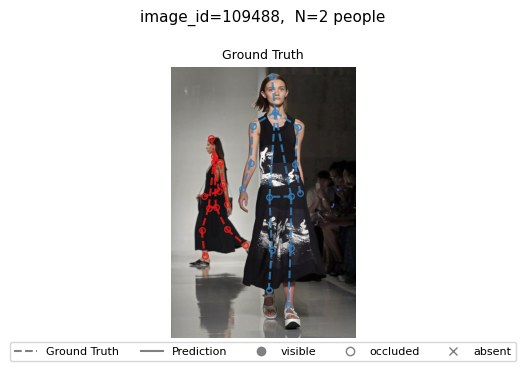

In [320]:
# Ground truth reference — same draw_pose format as all other figures
comparison_figure(
    [img_np],
    [[[(gt_kpts, vis, "gt")]]],
    col_titles=["Ground Truth"],
    suptitle=f"image_id={sample['image_id']},  N={gt_kpts.shape[0]} people",
    save_path=EVAL_DIR / "figures" / "b0_gt_reference.png",
)


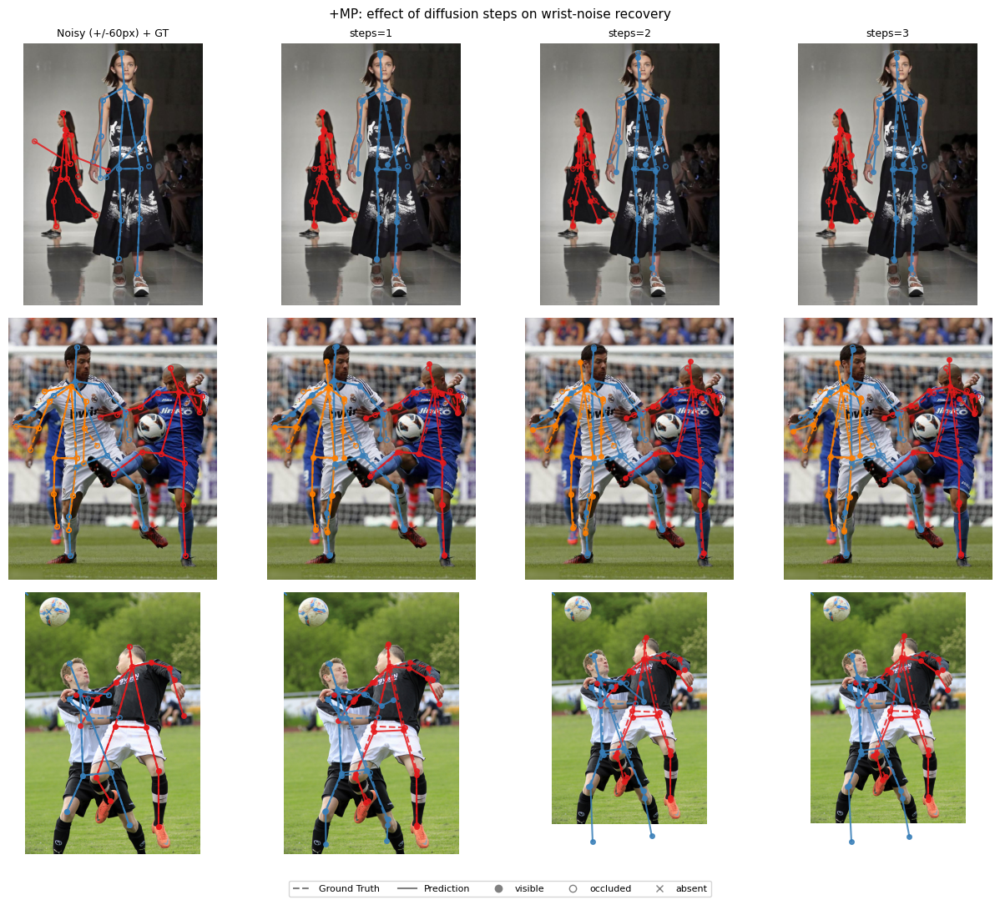

In [321]:

# Effect of diffusion steps on wrist-noise recovery (+MP model, 3 images)
torch.manual_seed(0)

img_np_list, panels_list = [], []
for s, gt, v, img in load_samples(SAMPLE_INDICES):
    noisy = gt.clone()
    noisy[:, J["left_wrist"],  :] += torch.randn(gt.shape[0], 2) * NOISE_STD
    noisy[:, J["right_wrist"], :] += torch.randn(gt.shape[0], 2) * NOISE_STD

    step_panels = [[(noisy, v, "pred"), (gt, v, "gt")]]
    for n in N_STEPS_LIST:
        refined = run_refine(module_mp, make_refine_batch(s, noisy), n_steps=n, noise_frac=NOISE_FRAC)
        step_panels.append([(gt, v, "gt_ref"), (refined, None, "pred")])

    img_np_list.append(img)
    panels_list.append(step_panels)

comparison_figure(
    img_np_list, panels_list,
    col_titles=[f"Noisy (+/-{NOISE_STD:.0f}px) + GT"] + [f"steps={n}" for n in N_STEPS_LIST],
    suptitle="+MP: effect of diffusion steps on wrist-noise recovery",
    save_path=EVAL_DIR / "figures" / "b1_ddim_steps.png",
)


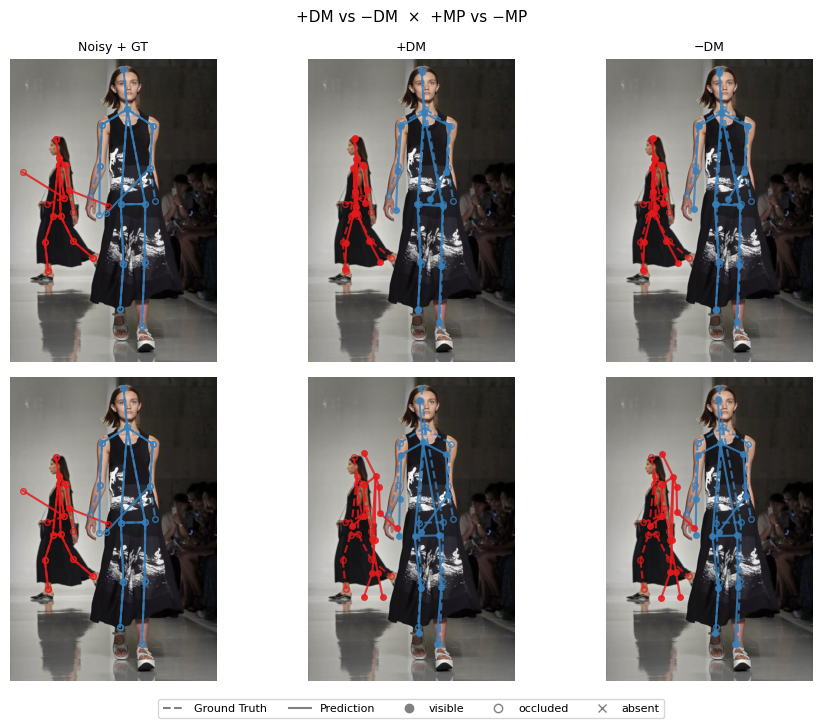

In [322]:

# +DM vs −DM  x  +MP vs -MP  (rows = model variant, cols = inference mode)
s, gt, v, img = load_samples([SAMPLE_INDICES[0]])[0]
torch.manual_seed(0)
noisy = gt.clone()
noisy[:, J["left_wrist"],  :] += torch.randn(gt.shape[0], 2) * NOISE_STD
noisy[:, J["right_wrist"], :] += torch.randn(gt.shape[0], 2) * NOISE_STD

img_np_list, panels_list = [], []
for _, module in [("+MP", module_mp), ("-MP", module_nomp)]:
    dm   = run_refine(module, make_refine_batch(s, noisy), n_steps=STEPS, raw_refiner=False, noise_frac=NOISE_FRAC)
    nodm = run_refine(module, make_refine_batch(s, noisy), n_steps=STEPS, raw_refiner=True,  noise_frac=NOISE_FRAC)
    img_np_list.append(img)
    panels_list.append([
        [(noisy, v, "pred"), (gt, v, "gt")],
        [(gt,    v, "gt_ref"), (dm,   None, "pred")],
        [(gt,    v, "gt_ref"), (nodm, None, "pred")],
    ])

comparison_figure(
    img_np_list, panels_list,
    col_titles=["Noisy + GT", "+DM", "−DM"],
    row_titles=["+MP", "-MP"],
    suptitle="+DM vs −DM  ×  +MP vs −MP",
    save_path=EVAL_DIR / "figures" / "b2_ddim_vs_raw.png",
)



## C — Critical Failure Cases

Synthetic corruptions applied to GT poses across 3 images; does the model recover?

1. **Same-person joint swap** — swap left/right wrists and ankles within each person
2. **Cross-person wrist swap** — swap wrists between person 0 and person 1 (requires ≥2 people)
3. **Large person corruption** — replace one person's entire pose with random pixel coordinates

Layout per experiment: `[GT | corrupted | +MP refined | −MP refined]`.  
Faint green overlay = GT reference. Color/marker legend shown below each figure.



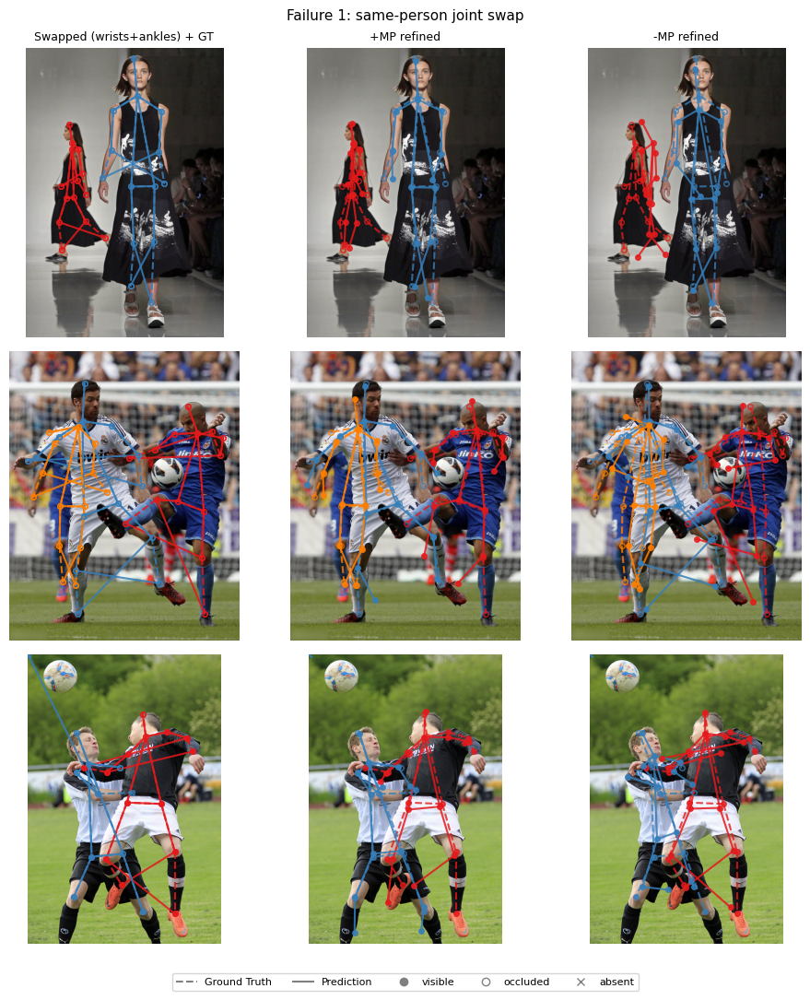

In [360]:

# Failure 1: same-person joint swap
samples_data = load_samples(SAMPLE_INDICES)
torch.manual_seed(0)

img_np_list, panels_list = [], []
for s, gt, v, img in samples_data:
    swapped = gt.clone()
    for ln, rn in [("left_wrist", "right_wrist"), ("left_ankle", "right_ankle")]:
        l, r = J[ln], J[rn]
        swapped[:, l], swapped[:, r] = gt[:, r].clone(), gt[:, l].clone()

    ref_mp   = run_refine(module_mp,   make_refine_batch(s, swapped), n_steps=STEPS, noise_frac=NOISE_FRAC)
    ref_nomp = run_refine(module_nomp, make_refine_batch(s, swapped), n_steps=STEPS, noise_frac=NOISE_FRAC)

    img_np_list.append(img)
    panels_list.append([
        [(swapped, v, "pred"), (gt, v, "gt")],
        [(gt,      v, "gt_ref"), (ref_mp,   None, "pred")],
        [(gt,      v, "gt_ref"), (ref_nomp, None, "pred")],
    ])

comparison_figure(
    img_np_list, panels_list,
    col_titles=["Swapped (wrists+ankles) + GT", "+MP refined", "-MP refined"],
    suptitle="Failure 1: same-person joint swap",
    save_path=EVAL_DIR / "figures" / "c_same_person_joint.png"
)

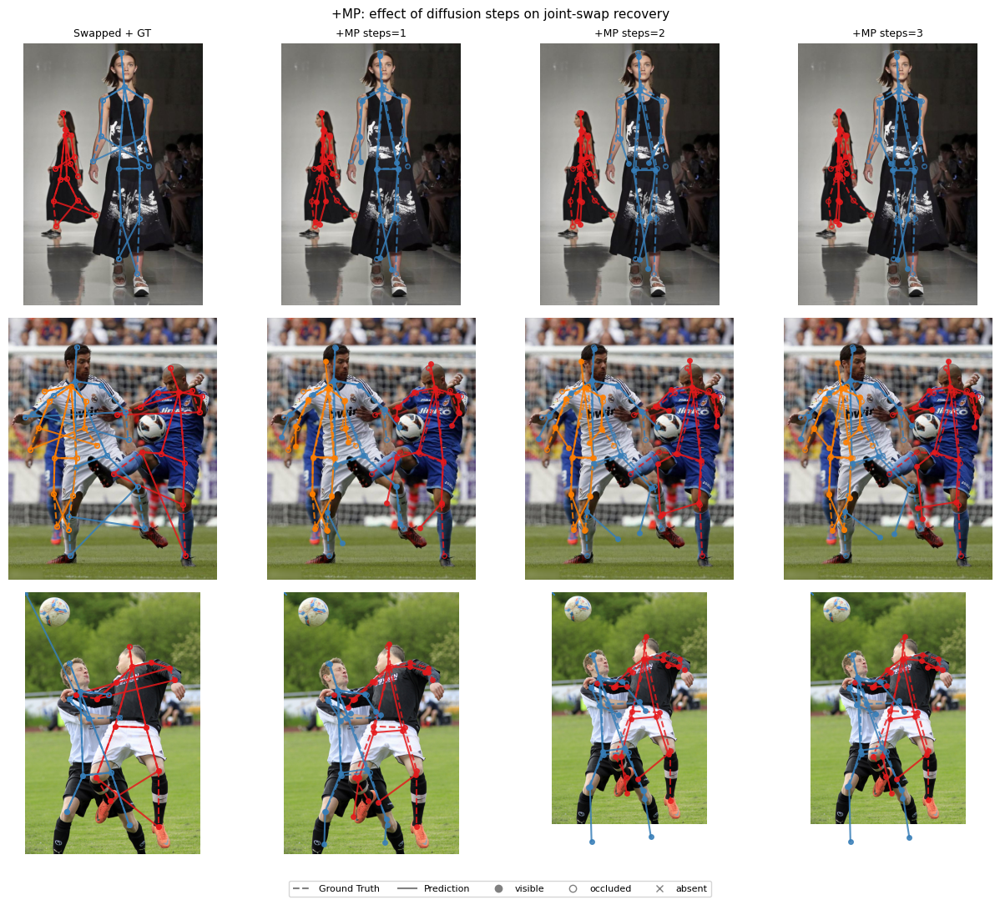

In [361]:

# Failure 1 cont'd: effect of diffusion steps on joint-swap recovery (+MP model)
img_np_list, panels_list = [], []
for s, gt, v, img in samples_data:
    swapped = gt.clone()
    for ln, rn in [("left_wrist", "right_wrist"), ("left_ankle", "right_ankle")]:
        l, r = J[ln], J[rn]
        swapped[:, l], swapped[:, r] = gt[:, r].clone(), gt[:, l].clone()

    step_panels = [[(swapped, v, "pred"), (gt, v, "gt")]]
    for n in FAIL_STEPS_LIST:
        refined = run_refine(module_mp, make_refine_batch(s, swapped), n_steps=n, noise_frac=NOISE_FRAC)
        step_panels.append([(gt, v, "gt_ref"), (refined, None, "pred")])

    img_np_list.append(img)
    panels_list.append(step_panels)

comparison_figure(
    img_np_list, panels_list,
    col_titles=["Swapped + GT"] + [f"+MP steps={n}" for n in FAIL_STEPS_LIST],
    suptitle="+MP: effect of diffusion steps on joint-swap recovery",
    save_path=EVAL_DIR / "figures" / "c_diffusion_steps_joint_swap.png"
)


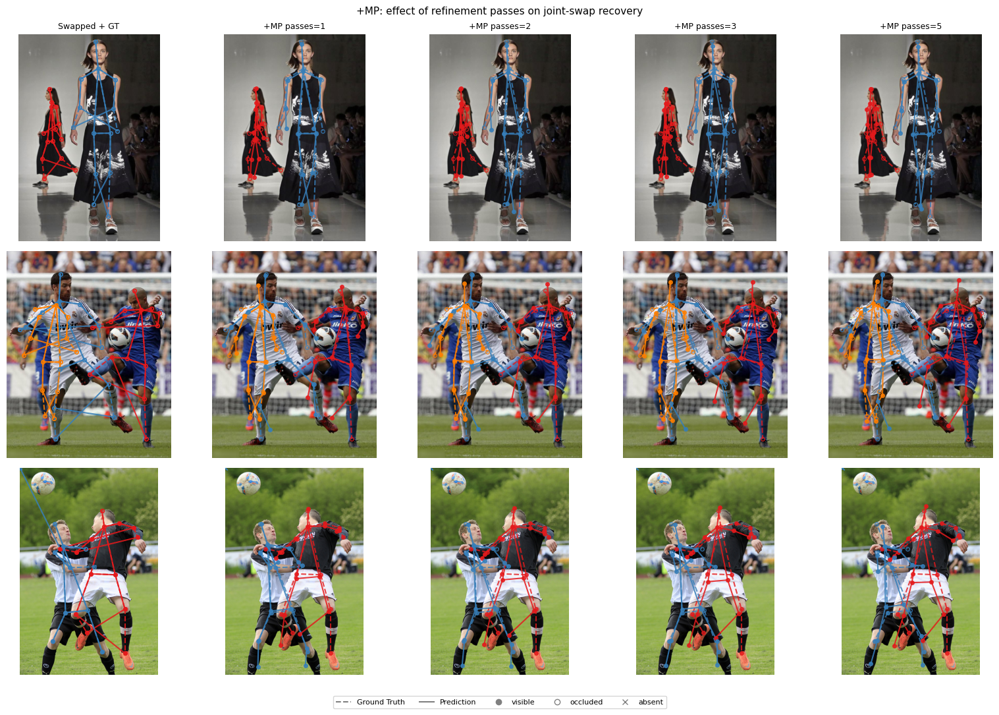

In [325]:

# Failure 1 cont'd: effect of refinement passes on joint-swap recovery (+MP model)
# Each pass feeds the previous output back into the refiner.
img_np_list, panels_list = [], []
for s, gt, v, img in samples_data:
    swapped = gt.clone()
    for ln, rn in [("left_wrist", "right_wrist"), ("left_ankle", "right_ankle")]:
        l, r = J[ln], J[rn]
        swapped[:, l], swapped[:, r] = gt[:, r].clone(), gt[:, l].clone()

    pass_panels = [[(swapped, v, "pred"), (gt, v, "gt")]]
    for n_passes in FAIL_PASSES_LIST:
        kpts = swapped
        for _ in range(n_passes):
            kpts = run_refine(module_mp, make_refine_batch(s, kpts), n_steps=STEPS, noise_frac=NOISE_FRAC)
        pass_panels.append([(gt, v, "gt_ref"), (kpts, None, "pred")])

    img_np_list.append(img)
    panels_list.append(pass_panels)

comparison_figure(
    img_np_list, panels_list,
    col_titles=["Swapped + GT"] + [f"+MP passes={n}" for n in FAIL_PASSES_LIST],
    suptitle="+MP: effect of refinement passes on joint-swap recovery",
    save_path=EVAL_DIR / "figures" / "c3_joint_swap_passes.png",
)



### 2 — Cross-person wrist swap

Swap the wrists of person 0 and person 1 across the scene.  
Tests whether the model uses inter-person context (+MP) to resolve cross-body confusion.



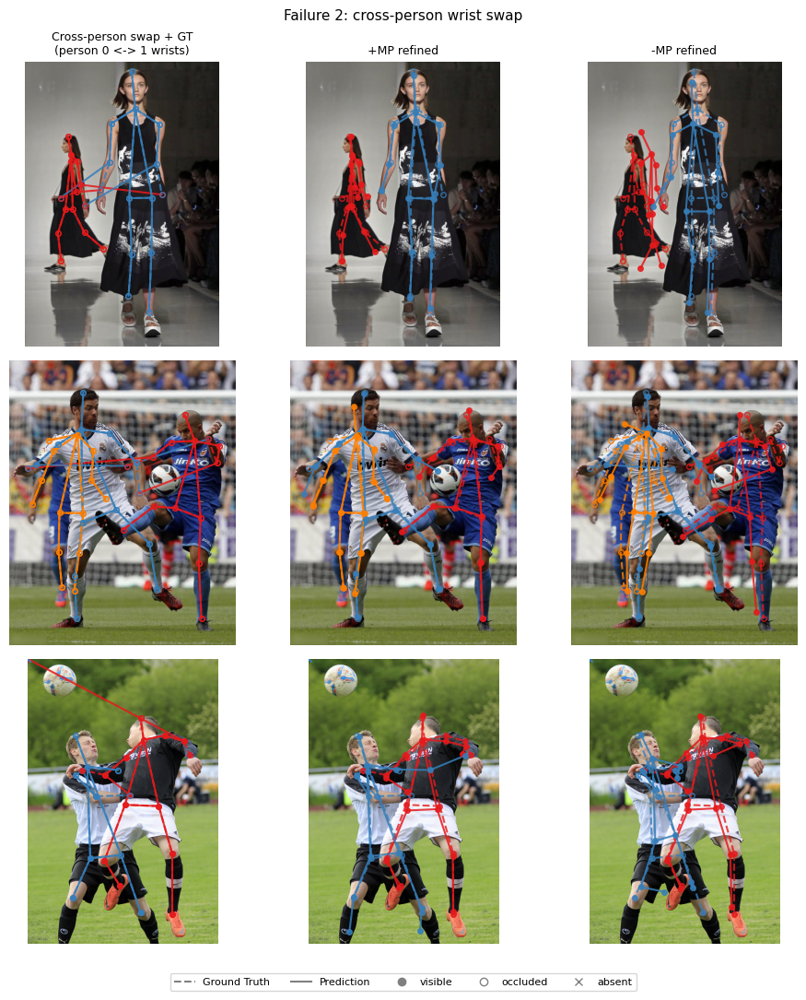

In [362]:

# Failure 2: cross-person wrist swap (skips images with fewer than 2 people)
img_np_list, panels_list = [], []
for s, gt, v, img in samples_data:
    if gt.shape[0] < 2:
        continue
    swapped = gt.clone()
    for joint_name in ("left_wrist", "right_wrist"):
        jj = J[joint_name]
        swapped[0, jj], swapped[1, jj] = gt[1, jj].clone(), gt[0, jj].clone()

    ref_mp   = run_refine(module_mp,   make_refine_batch(s, swapped), n_steps=STEPS, noise_frac=NOISE_FRAC)
    ref_nomp = run_refine(module_nomp, make_refine_batch(s, swapped), n_steps=STEPS, noise_frac=NOISE_FRAC)

    img_np_list.append(img)
    panels_list.append([
        [(swapped, v, "pred"), (gt, v, "gt")],
        [(gt,      v, "gt_ref"), (ref_mp,   None, "pred")],
        [(gt,      v, "gt_ref"), (ref_nomp, None, "pred")],
    ])

if not img_np_list:
    print("No SAMPLE_INDICES have >=2 people -- adjust SAMPLE_INDICES in cell 8.")
else:
    comparison_figure(
        img_np_list, panels_list,
        col_titles=["Cross-person swap + GT\n(person 0 <-> 1 wrists)", "+MP refined", "-MP refined"],
        suptitle="Failure 2: cross-person wrist swap",
        save_path=EVAL_DIR / "figures" / "c_cross_person_joint_swap.png"
    )

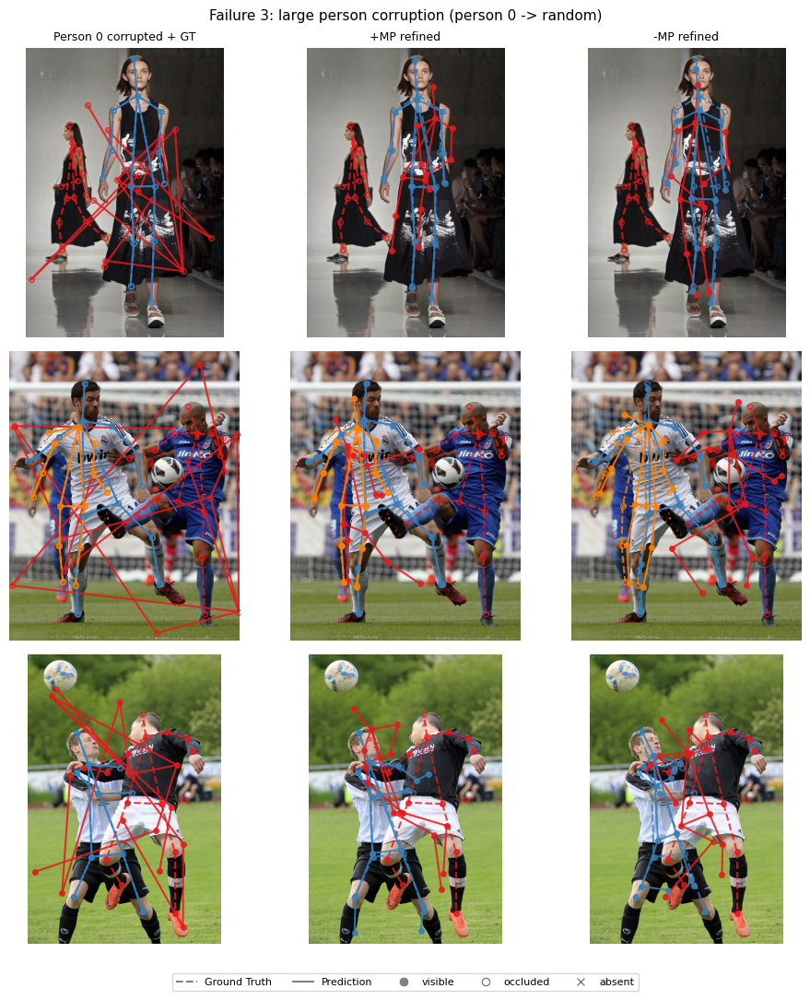

In [363]:

# Failure 3: replace person 0's pose with random coordinates
torch.manual_seed(1)

img_np_list, panels_list = [], []
for s, gt, v, img in samples_data:
    img_h, img_w = read_image_size(s["img_path"])
    corrupted = gt.clone()
    corrupted[0] = torch.rand(14, 2) * torch.tensor([img_w, img_h], dtype=torch.float)

    ref_mp   = run_refine(module_mp,   make_refine_batch(s, corrupted), n_steps=STEPS, noise_frac=NOISE_FRAC)
    ref_nomp = run_refine(module_nomp, make_refine_batch(s, corrupted), n_steps=STEPS, noise_frac=NOISE_FRAC)

    img_np_list.append(img)
    panels_list.append([
        [(corrupted, v, "pred"), (gt, v, "gt")],
        [(gt,        v, "gt_ref"), (ref_mp,   None, "pred")],
        [(gt,        v, "gt_ref"), (ref_nomp, None, "pred")],
    ])

comparison_figure(
    img_np_list, panels_list,
    col_titles=["Person 0 corrupted + GT", "+MP refined", "-MP refined"],
    suptitle="Failure 3: large person corruption (person 0 -> random)",
    save_path=EVAL_DIR / "figures" / "c_large_corruption.png"

)

## D — Quantitative Results

Architecture ablation and inference-parameter ablation results.


In [328]:
INFERENCE_DM_CSV  = Path("results/inference-ablation/ddim/results.csv")
INFERENCE_RAW_CSV = Path("results/inference-ablation/raw/results.csv")
ARCH_CSV          = Path("results/arch-ablation/results.csv")

def load_results(path: Path) -> pd.DataFrame | None:
    if not path.exists():
        print(f"Not found (run sweep first): {path}")
        return None
    df = pd.read_csv(path)
    print(f"Loaded {len(df)} rows from {path}")
    return df

df_dm  = load_results(INFERENCE_DM_CSV)
df_raw = load_results(INFERENCE_RAW_CSV)
df_arch = load_results(ARCH_CSV)


Loaded 9 rows from results/inference-ablation/ddim/results.csv
Loaded 9 rows from results/inference-ablation/raw/results.csv
Loaded 4 rows from results/arch-ablation/results.csv


In [356]:
# Inference ablation — +DM mode
if df_dm is not None:
    display_cols = ["task_id", "steps", "noise_frac", "passes", "guidance_scale",
                    "crowdpose/AP", "crowdpose/AP .5", "crowdpose/AP .75"]
    wishful_display_cols = ["Task", "Steps", "Noise", "Passes", "CFG",
                    "AP", "AP50", "AP75"]
    
    col_map = {c_from: c_to for (c_from, c_to) in zip(display_cols, wishful_display_cols)}
    df_dm_2 = df_dm[[c for c in display_cols if c in df_dm.columns]].rename(columns=col_map)
    display(df_dm[[c for c in display_cols if c in df_dm.columns]])

    df_dm_2.to_csv(EVAL_DIR / "tables" / "d_inference_ablation_dm.csv", index=False)
    print(df_dm_2.to_latex())


,task_id,steps,noise_frac,passes,guidance_scale,crowdpose/AP,crowdpose/AP .5,crowdpose/AP .75
0,1,1,0.2,1,1.0,0.6568,0.9114,0.7117
1,2,2,0.2,1,1.0,0.5251,0.8255,0.5407
2,3,3,0.2,1,1.0,0.5009,0.8036,0.5138
3,4,1,0.1,1,1.0,0.6598,0.9125,0.7142
4,5,1,0.4,1,1.0,0.5998,0.8857,0.6390
5,6,1,0.2,2,1.0,0.4860,0.7914,0.4917
6,7,1,0.2,3,1.0,0.3797,0.6904,0.3657
7,8,1,0.2,1,2.0,0.0972,0.2310,0.0728
8,9,1,0.2,1,3.0,0.0321,0.0994,0.0144


\begin{tabular}{lrrrrrrrr}
\toprule
 & Task & Steps & Noise & Passes & CFG & AP & AP50 & AP75 \\
\midrule
0 & 1 & 1 & 0.200000 & 1 & 1.000000 & 0.656800 & 0.911400 & 0.711700 \\
1 & 2 & 2 & 0.200000 & 1 & 1.000000 & 0.525100 & 0.825500 & 0.540700 \\
2 & 3 & 3 & 0.200000 & 1 & 1.000000 & 0.500900 & 0.803600 & 0.513800 \\
3 & 4 & 1 & 0.100000 & 1 & 1.000000 & 0.659800 & 0.912500 & 0.714200 \\
4 & 5 & 1 & 0.400000 & 1 & 1.000000 & 0.599800 & 0.885700 & 0.639000 \\
5 & 6 & 1 & 0.200000 & 2 & 1.000000 & 0.486000 & 0.791400 & 0.491700 \\
6 & 7 & 1 & 0.200000 & 3 & 1.000000 & 0.379700 & 0.690400 & 0.365700 \\
7 & 8 & 1 & 0.200000 & 1 & 2.000000 & 0.097200 & 0.231000 & 0.072800 \\
8 & 9 & 1 & 0.200000 & 1 & 3.000000 & 0.032100 & 0.099400 & 0.014400 \\
\bottomrule
\end{tabular}



In [330]:
# Architecture ablation table
if df_arch is not None:
    display_cols = ["task_id", "use_message_passing", "raw_refiner",
                    "crowdpose/AP", "crowdpose/AP .5", "crowdpose/AP .75"]
    display(
        df_arch[[c for c in display_cols if c in df_arch.columns]]
        .rename(columns={"raw_refiner": "no_DM"})
    )

    df_arch.to_csv(EVAL_DIR / "tables" / "d_arch_comparison_models.csv", index=False)

,task_id,use_message_passing,no_DM,crowdpose/AP,crowdpose/AP .5,crowdpose/AP .75
0,1,True,False,0.6569,0.9117,0.7114
1,2,True,True,0.6626,0.9125,0.7149
2,3,False,False,0.2029,0.3818,0.1908
3,4,False,True,0.2043,0.3828,0.1910


In [357]:

# ── Full metrics: detector baseline vs. all refinement variants ───────────────
METRIC_COLS = [
    "crowdpose/AP", "crowdpose/AP .5", "crowdpose/AP .75",
    "crowdpose/AR", "crowdpose/AR .5", "crowdpose/AR .75",
    "crowdpose/AP(E)", "crowdpose/AP(M)", "crowdpose/AP(H)",
]
DISPLAY_NAMES = {
    "crowdpose/AP":     "AP",     "crowdpose/AP .5":  "AP50",
    "crowdpose/AP .75": "AP75",   "crowdpose/AR":     "AR",
    "crowdpose/AR .5":  "AR50",   "crowdpose/AR .75": "AR75",
    "crowdpose/AP(E)":  "AP(E)",  "crowdpose/AP(M)":  "AP(M)",
    "crowdpose/AP(H)":  "AP(H)",
}

rtmpose_raw  = json.load(open(Path("results/rtmpose_crowdpose_benchmark/results.json")))
baseline_row = {k: round(v, 4) for k, v in rtmpose_raw.items() if k in METRIC_COLS}

def _bool(v):
    return str(v).lower() == "true"

def arch_label(r):
    mp  = "+MP"  if _bool(r["use_message_passing"]) else "−MP"
    ref = "−DM"  if _bool(r["raw_refiner"])         else "+DM"
    return f"{mp} / {ref}"

rows = [{"Model": "RTMPose-m", **baseline_row}]
if df_arch is not None:
    for _, r in df_arch.iterrows():
        rows.append({"Model": arch_label(r), **{k: round(r[k], 4) for k in METRIC_COLS if k in r}})

df_compare = (
    pd.DataFrame(rows)
    .set_index("Model")
    .rename(columns=DISPLAY_NAMES)
)

(df_compare
 .style
 .highlight_max(axis=0, color="#c8f0c8")
 .highlight_min(axis=0, color="#f0c8c8")
 .format("{:.4f}")
 .set_caption(
     "CrowdPose val — detector baseline vs. diffusion refinement  "
     "(green = best per column, red = worst)"
 )
)

df_compare.to_csv(EVAL_DIR / "tables" / "d_arch_comparison.csv")
print(df_compare.to_latex())


\begin{tabular}{lrrrrrrrrr}
\toprule
 & AP & AP50 & AP75 & AR & AR50 & AR75 & AP(E) & AP(M) & AP(H) \\
Model &  &  &  &  &  &  &  &  &  \\
\midrule
RTMPose-m & 0.705700 & 0.841300 & 0.765100 & 0.788100 & 0.923000 & 0.842600 & 0.799400 & 0.718800 & 0.581800 \\
+MP / +DM & 0.656900 & 0.911700 & 0.711400 & 0.700500 & 0.925600 & 0.751600 & 0.647800 & 0.661400 & 0.657300 \\
+MP / −DM & 0.662600 & 0.912500 & 0.714900 & 0.707000 & 0.927600 & 0.760000 & 0.653800 & 0.669300 & 0.662600 \\
−MP / +DM & 0.202900 & 0.381800 & 0.190800 & 0.315900 & 0.514700 & 0.321900 & 0.206900 & 0.190900 & 0.270600 \\
−MP / −DM & 0.204300 & 0.382800 & 0.191000 & 0.317100 & 0.516500 & 0.322300 & 0.207700 & 0.191200 & 0.271900 \\
\bottomrule
\end{tabular}



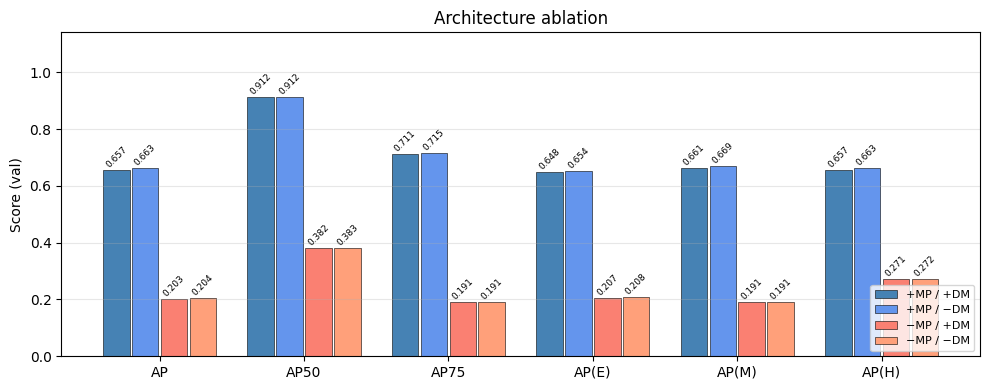

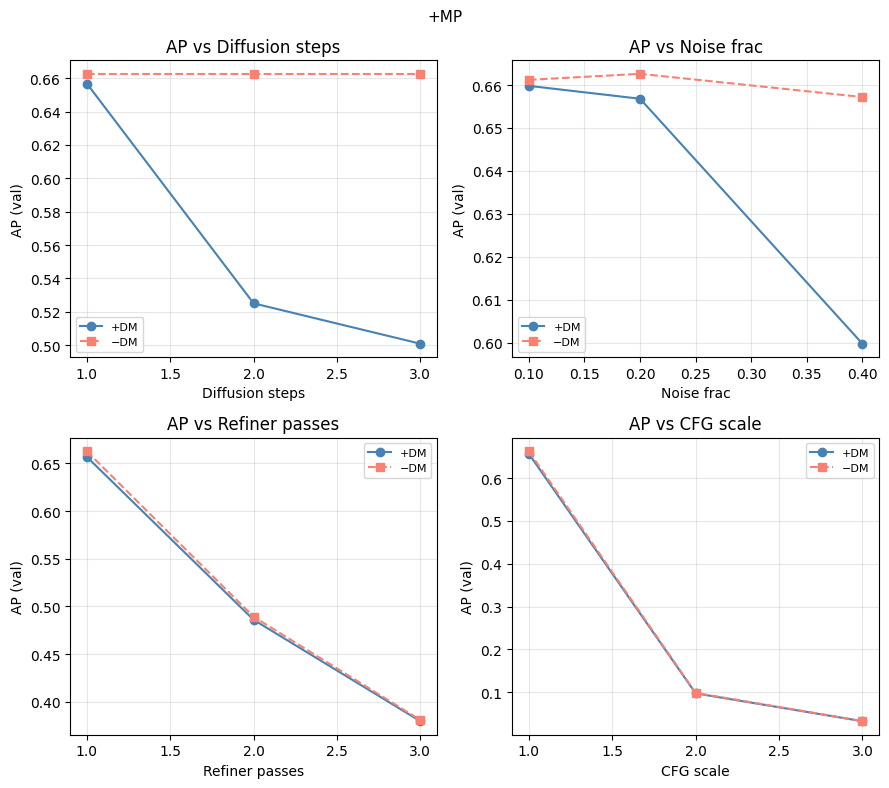

In [359]:
# ── Architecture ablation: grouped bar chart over multiple AP metrics ─────────
if df_arch is not None:
    ARCH_METRICS = [
        ("crowdpose/AP",     "AP"),
        ("crowdpose/AP .5",  "AP50"),
        ("crowdpose/AP .75", "AP75"),
        ("crowdpose/AP(E)",  "AP(E)"),
        ("crowdpose/AP(M)",  "AP(M)"),
        ("crowdpose/AP(H)",  "AP(H)"),
    ]
    ARCH_METRICS = [(c, n) for c, n in ARCH_METRICS if c in df_arch.columns]

    model_labels = df_arch.apply(
        lambda r: f"{'+MP' if r['use_message_passing'] else '−MP'} / {'−DM' if r['raw_refiner'] else '+DM'}",
        axis=1,
    ).tolist()
    n_models  = len(model_labels)
    n_metrics = len(ARCH_METRICS)

    x      = np.arange(n_metrics)
    width  = 0.8 / n_models
    colors = ["steelblue", "cornflowerblue", "salmon", "lightsalmon"]

    fig, ax = plt.subplots(figsize=(10, 4))
    for i, (label, color) in enumerate(zip(model_labels, colors)):
        vals   = [df_arch.iloc[i][c] for c, _ in ARCH_METRICS]
        offset = (i - n_models / 2 + 0.5) * width
        bars   = ax.bar(x + offset, vals, width=width * 0.92,
                        label=label, color=color, edgecolor="black", linewidth=0.4)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.002,
                    f"{val:.3f}", ha="center", va="bottom", fontsize=6.5, rotation=45)

    ax.set_xticks(x)
    ax.set_xticklabels([n for _, n in ARCH_METRICS])
    ax.set_ylabel("Score (val)")
    ax.set_title("Architecture ablation")
    ax.legend(fontsize=8, loc="lower right")
    ax.set_ylim(0, max(df_arch[[c for c, _ in ARCH_METRICS]].max()) * 1.25)
    ax.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.savefig(EVAL_DIR / "figures" / "d_arch_ablation_ap.png", dpi=150, bbox_inches="tight")
    plt.show()

# ── Inference ablation: AP vs each varied parameter ───────────────────────────
if df_dm is not None and df_raw is not None:
    params   = [
        ("steps",          "Diffusion steps"),
        ("noise_frac",     "Noise frac"),
        ("passes",         "Refiner passes"),
        ("guidance_scale", "CFG scale"),
    ]
    baseline = {"steps": 1, "noise_frac": 0.2, "passes": 1, "guidance_scale": 1.0}
    ap_col   = "crowdpose/AP"

    def at_baseline(df, vary_col):
        mask = pd.Series([True] * len(df), index=df.index)
        for c, v in baseline.items():
            if c == vary_col:
                continue
            if isinstance(v, float):
                mask &= (df[c] - v).abs() < 1e-6
            else:
                mask &= (df[c] == v)
        return df[mask].sort_values(vary_col)

    plt.figure(figsize=(9, 8))
    for i, (col, label) in enumerate(params):
        plt.subplot(2, 2, i+1)
        ax = plt.gca()
        sub_dm  = at_baseline(df_dm,  col)
        sub_raw = at_baseline(df_raw, col)
        ax.plot(sub_dm[col],  sub_dm[ap_col],  "o-",  label="+DM", color="steelblue", linewidth=1.5)
        ax.plot(sub_raw[col], sub_raw[ap_col], "s--", label="−DM", color="salmon",    linewidth=1.5)
        ax.set_xlabel(label)
        ax.set_ylabel("AP (val)")
        ax.set_title(f"AP vs {label}")
        ax.legend(fontsize=8)
        ax.grid(alpha=0.3)

    plt.suptitle("+MP", fontsize=11)
    plt.tight_layout()
    plt.savefig(EVAL_DIR / "figures" / "d_inference_ablation_ap.png", dpi=150, bbox_inches="tight")
    plt.show()


## E — DINO Cross-Attention Maps

### What is the DINO conditioner?

When image conditioning is enabled, each keypoint node receives a local visual feature vector sampled from a frozen **DINOv3 ConvNeXt-Small** backbone. Two feature levels are used:

- **Stage 1** (96 channels, stride 4) — fine-grained spatial texture, high resolution
- **Stage 4** (768 channels, stride 32) — high-level semantic features, low resolution

The `AttentionDinoConditioner` fuses these two levels and produces a per-keypoint feature through the following steps:

1. **Patch fusion** — stage-4 features are upsampled to stage-1 resolution, concatenated (864-d per patch), and projected to `inner_dim` via a small MLP. Each spatial cell of the stage-1 grid becomes one *patch token*.
2. **Cross-attention** — each keypoint node queries the full set of patch tokens. The attention score between a node and a patch is the scaled dot product of their features, plus a learned **relative-position bias** (the 2D patch-to-node offset is projected to a per-head scalar). This lets each head specialise on a different spatial relationship — e.g. one head may focus on nearby patches, another on the whole limb region.
3. **Self-attention over joints** — after gathering image context, the K joints of each person attend to one another, allowing the conditioner to propagate appearance information across the skeleton.

The output is a `dim_image_cond`-dimensional vector per keypoint, which is injected into every GNN layer as the visual feature $v_i$.

### What does this section visualise?

For a chosen joint (e.g. left wrist) we extract the raw per-head cross-attention weights and scatter-plot them over the image, with each patch coloured by its attention weight (hot colormap: bright = high weight). The cyan ★ marks the queried keypoint location.

We run this for two scenarios side-by-side:
- **GT** — joint at its correct position
- **Swapped** — left/right wrists and ankles exchanged

The goal is to understand whether the conditioner attends to *semantically meaningful* image regions (e.g. the actual wrist area) and whether the attended region shifts when the joint position is wrong — giving insight into how much image evidence the model uses when deciding how to refine a joint.


In [333]:
from src.model import AttentionDinoConditioner, pixel_to_grid_sample_coords


@torch.no_grad()
def get_cross_attn_maps(module, sample, kpt_px):
    """Extract per-head cross-attention weights from AttentionDinoConditioner.

    Args:
        module:  PoseDiffusionModule with an AttentionDinoConditioner
        sample:  val_dataset sample dict (image_id, img_path, ...)
        kpt_px:  (N, 14, 2) pixel keypoints to query attention for

    Returns:
        attn_per_head: (num_heads, N*14, P) — raw per-head weights
        patch_pos_px:  (P, 2) — patch centres in pixel coords (x, y)
        img_hw:        (H, W) tuple
        H_s, W_s:      stage-1 spatial grid shape
    """
    cond = module.dino_conditioner
    assert isinstance(cond, AttentionDinoConditioner), (
        "module.dino_conditioner must be an AttentionDinoConditioner"
    )

    image_id = sample["image_id"]
    img_h, img_w = read_image_size(sample["img_path"])
    device = next(cond.parameters()).device

    # ── build patch features + positions ────────────────────────────────────
    spatial_maps, semantic_maps = cond._load_maps([image_id], device)
    patch_feats, patch_pos = cond._fuse_patches(spatial_maps[0], semantic_maps[0])
    # patch_pos: (P, 2) in [-1, 1]; patch_feats: (P, inner_dim)

    C_s, H_s, W_s = spatial_maps[0].shape
    P = H_s * W_s

    padded_feats = patch_feats.unsqueeze(0)   # (1, P, inner_dim)
    padded_pos   = patch_pos.unsqueeze(0)     # (1, P, 2)
    patch_key_mask = torch.zeros(1, P, dtype=torch.bool, device=device)  # no padding (B=1)

    # ── normalise keypoint positions ────────────────────────────────────────
    N, K = kpt_px.shape[0], kpt_px.shape[1]
    kpt_t = kpt_px.unsqueeze(0).to(device).float()      # (1, N, K, 2)
    img_hw_t = torch.tensor([[img_h, img_w]], dtype=torch.float32, device=device)
    node_pos_norm = pixel_to_grid_sample_coords(kpt_t, img_hw_t.view(1, 1, 1, 2))  # (1, N, K, 2)
    node_pos_flat = node_pos_norm.view(1, N * K, 2)    # (1, NK, 2)

    # ── replicate rel-pos bias ───────────────────────────────────────────────
    B, NK, max_P = 1, N * K, P
    H_heads = cond.num_heads

    rel_pos  = padded_pos.unsqueeze(1) - node_pos_flat.unsqueeze(2)  # (1, NK, P, 2)
    rel_bias = cond.cross_rel_pos_bias(rel_pos)                       # (1, NK, P, H)
    rel_bias = rel_bias.permute(0, 3, 1, 2).reshape(H_heads, NK, P)  # (H, NK, P) — B=1

    pad_inf = patch_key_mask.view(1, 1, 1, P).expand(1, H_heads, NK, P).reshape(H_heads, NK, P)
    rel_bias = rel_bias.masked_fill(pad_inf, float("-inf"))

    # ── node query features ─────────────────────────────────────────────────
    h = cond.node_pos_proj(node_pos_flat)   # (1, NK, inner_dim)

    # ── cross-attention with per-head weights ────────────────────────────────
    # need_weights=True + average_attn_weights=False → (B, NK, P) per head
    _, attn_w = cond.cross_attn(
        h,             # Q
        padded_feats,  # K
        padded_feats,  # V
        attn_mask=rel_bias,
        need_weights=True,
        average_attn_weights=False,
    )
    # attn_w: (B*H, NK, P) when batch_first=True and average=False
    attn_per_head = attn_w.view(H_heads, NK, P).cpu()  # (H, NK, P)

    # ── convert patch positions back to pixel space ──────────────────────────
    patch_pos_cpu = patch_pos.cpu()                 # (P, 2), x/y in [-1, 1]
    px_x = (patch_pos_cpu[:, 0] + 1) / 2 * img_w   # (P,)
    px_y = (patch_pos_cpu[:, 1] + 1) / 2 * img_h   # (P,)
    patch_pos_px = torch.stack([px_x, px_y], dim=1)  # (P, 2)

    return attn_per_head, patch_pos_px, (img_h, img_w), H_s, W_s


In [334]:
@torch.no_grad()
def get_self_attn_maps(module, sample, kpt_px):
    """Extract per-head self-attention weights over joints from AttentionDinoConditioner.

    Runs the full conditioner forward up through cross-attention to obtain the
    node features h, then calls self_attn with need_weights=True so we can inspect
    which joints attend to which.

    Returns:
        attn_per_head: (N, num_heads, K, K) — attn[person, head, query_joint, key_joint]
    """
    cond = module.dino_conditioner
    assert isinstance(cond, AttentionDinoConditioner), (
        "module.dino_conditioner must be an AttentionDinoConditioner"
    )

    image_id = sample["image_id"]
    img_h, img_w = read_image_size(sample["img_path"])
    device = next(cond.parameters()).device

    N, K = kpt_px.shape[0], kpt_px.shape[1]
    kpt_t    = kpt_px.unsqueeze(0).to(device).float()       # (1, N, K, 2)
    img_hw_t = torch.tensor([[img_h, img_w]], dtype=torch.float32, device=device)
    node_pos_norm = pixel_to_grid_sample_coords(kpt_t, img_hw_t.view(1, 1, 1, 2))  # (1, N, K, 2)
    node_pos_flat = node_pos_norm.view(1, N * K, 2)          # (1, NK, 2)

    # Build patch batch
    spatial_maps, semantic_maps = cond._load_maps([image_id], device)
    patch_feats, patch_pos = cond._fuse_patches(spatial_maps[0], semantic_maps[0])
    P = patch_feats.shape[0]
    padded_feats   = patch_feats.unsqueeze(0)                 # (1, P, inner_dim)
    padded_pos     = patch_pos.unsqueeze(0)                   # (1, P, 2)
    patch_key_mask = torch.zeros(1, P, dtype=torch.bool, device=device)

    # Node features → cross-attend (reuse existing method)
    h = cond.node_pos_proj(node_pos_flat)                     # (1, NK, inner_dim)
    h = h + cond._cross_attend(h, padded_feats, node_pos_flat, padded_pos, patch_key_mask)

    # Reshape to (N, K, inner_dim) for B=1
    joint_pos = node_pos_norm.view(N, K, 2)
    h         = h.view(N, K, cond.inner_dim)

    # Replicate _self_attend_joints input: add absolute position encoding
    q = h + cond.joint_pos_proj(joint_pos)                   # (N, K, inner_dim)

    # Self-attention with per-head weights
    # With batch_first=True, average_attn_weights=False → (N*H, K, K)
    _, attn_w = cond.self_attn(
        q, q, q,
        need_weights=True,
        average_attn_weights=False,
    )
    H_heads = cond.num_heads
    return attn_w.view(N, H_heads, K, K).cpu()               # (N, H, K, K)


/tmp/ipykernel_1205064/960920858.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.97, 0.95])


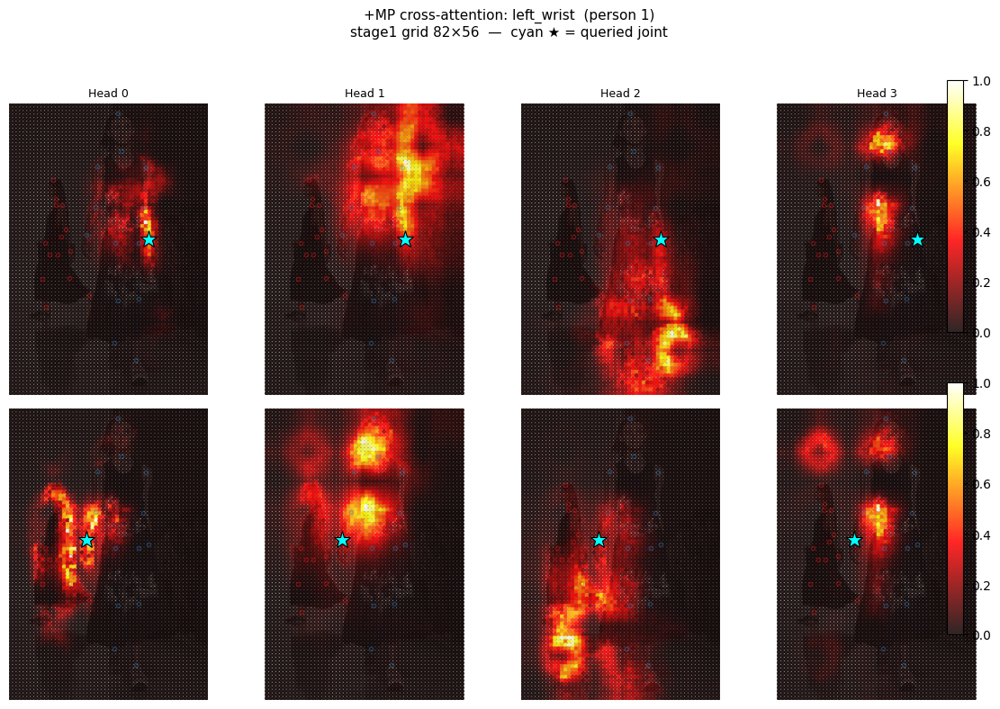

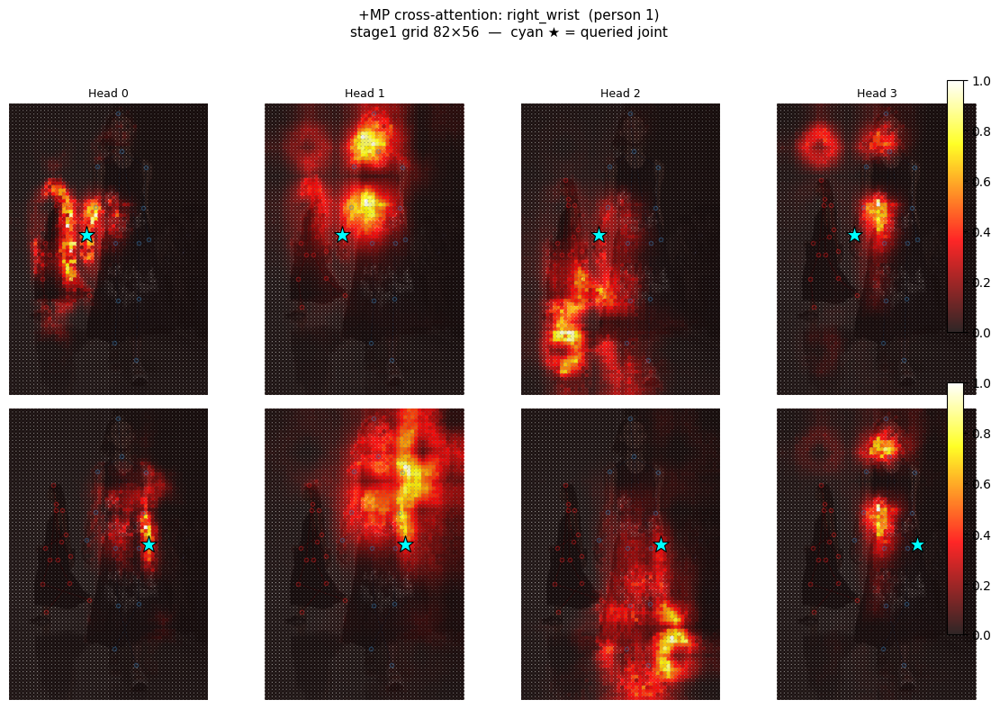

In [335]:
import matplotlib.cm as cm
import matplotlib.colors as mcolors

# ── Config ────────────────────────────────────────────────────────────────────
ATTN_SAMPLE_IDX = SAMPLE_INDICES[0]
ATTN_PERSON     = 1
ATTN_JOINTS     = ["left_wrist", "right_wrist"]

# ── Build GT and swapped keypoints ───────────────────────────────────────────
s_attn, gt_attn, v_attn, img_attn = load_samples([ATTN_SAMPLE_IDX])[0]
swapped_attn = gt_attn.clone()
for ln, rn in [("left_wrist", "right_wrist"), ("left_ankle", "right_ankle")]:
    l, r = J[ln], J[rn]
    swapped_attn[:, l], swapped_attn[:, r] = gt_attn[:, r].clone(), gt_attn[:, l].clone()

scenarios = [("GT", gt_attn), ("Swapped", swapped_attn)]
H_heads   = module_mp.dino_conditioner.num_heads

for joint_name in ATTN_JOINTS:
    joint_idx = J[joint_name]
    node_idx  = ATTN_PERSON * 14 + joint_idx

    fig, axes = plt.subplots(
        len(scenarios), H_heads,
        figsize=(3 * H_heads, 4 * len(scenarios)),
        squeeze=False,
    )

    for row, (label, kpt_px) in enumerate(scenarios):
        attn_per_head, patch_pos_px, (img_h, img_w), H_s, W_s = get_cross_attn_maps(
            module_mp, s_attn, kpt_px
        )
        kpt_loc = kpt_px[ATTN_PERSON, joint_idx].numpy()

        for h_idx in range(H_heads):
            ax = axes[row, h_idx]
            ax.imshow(img_attn, alpha=0.6)
            draw_pose(ax, kpt_px, v_attn, alpha=0.4, lw=1.0, ms=3)

            weights = attn_per_head[h_idx, node_idx].numpy()
            w_min, w_max = weights.min(), weights.max()
            w_norm = (weights - w_min) / (w_max - w_min + 1e-12)

            sc = ax.scatter(
                patch_pos_px[:, 0].numpy(),
                patch_pos_px[:, 1].numpy(),
                c=w_norm, cmap="hot", s=12, alpha=0.85, linewidths=0, zorder=2,
            )
            ax.plot(kpt_loc[0], kpt_loc[1], "*",
                    color="cyan", markersize=14, markeredgecolor="black",
                    markeredgewidth=0.8, zorder=5)

            ax.set_xlim(0, img_w)
            ax.set_ylim(img_h, 0)
            ax.axis("off")
            if row == 0:
                ax.set_title(f"Head {h_idx}", fontsize=9)
            if h_idx == 0:
                ax.set_ylabel(label, fontsize=10)

        cb_ax = fig.add_axes([
            axes[row, -1].get_position().x1 + 0.01,
            axes[row, -1].get_position().y0,
            0.015,
            axes[row, -1].get_position().height,
        ])
        fig.colorbar(sc, cax=cb_ax)

    fig.suptitle(
        f"+MP cross-attention: {joint_name}  (person {ATTN_PERSON})\n"
        f"stage1 grid {H_s}×{W_s}  —  cyan ★ = queried joint",
        fontsize=11,
    )
    plt.tight_layout(rect=[0, 0, 0.97, 0.95])
    plt.savefig(EVAL_DIR / "figures" / f"e_cross_attn_{joint_name}_person{ATTN_PERSON}.png", dpi=150, bbox_inches="tight")
    plt.show()


/tmp/ipykernel_1205064/4280961391.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.97, 0.95])


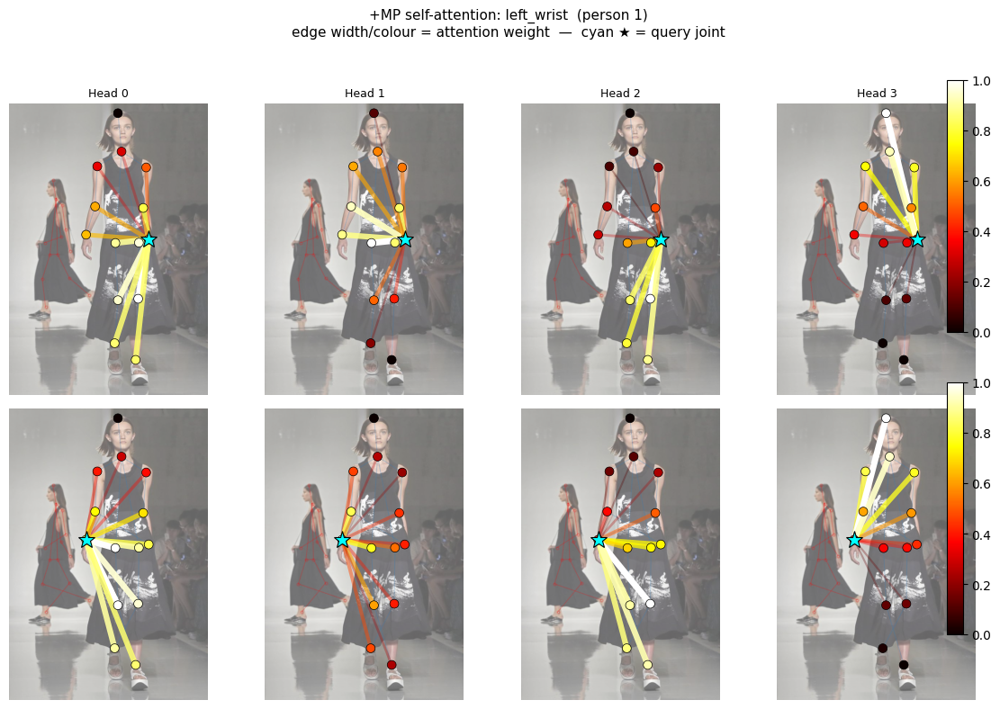

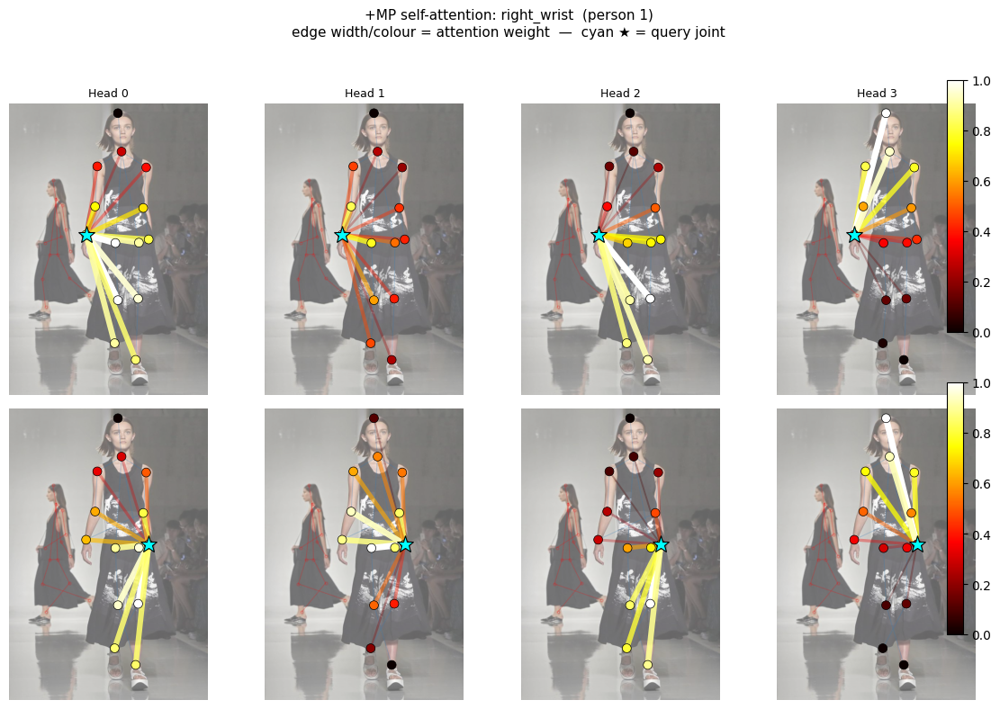

In [336]:
img_h_vis, img_w_vis = img_attn.shape[:2]
_hot = plt.cm.hot

for joint_name in ATTN_JOINTS:
    joint_idx = J[joint_name]

    fig, axes = plt.subplots(
        len(scenarios), H_heads,
        figsize=(3 * H_heads, 4 * len(scenarios)),
        squeeze=False,
    )

    for row, (label, kpt_px) in enumerate(scenarios):
        attn_per_head = get_self_attn_maps(module_mp, s_attn, kpt_px)
        # attn_per_head: (N, H, K, K)

        kpt_p     = kpt_px[ATTN_PERSON].numpy()       # (K, 2) pixel coords
        kpt_query = kpt_p[joint_idx]                   # (2,)

        for h_idx in range(H_heads):
            ax = axes[row, h_idx]
            ax.imshow(img_attn, alpha=0.6)
            draw_pose(ax, kpt_px, v_attn, alpha=0.25, lw=0.8, ms=2)

            weights = attn_per_head[ATTN_PERSON, h_idx, joint_idx].numpy()  # (K,)
            w_norm  = (weights - weights.min()) / (weights.max() - weights.min() + 1e-12)

            # Attention edges: query_joint → every other joint
            for k_idx in range(14):
                if k_idx == joint_idx:
                    continue
                w = float(w_norm[k_idx])
                if w < 0.05:
                    continue
                ax.plot(
                    [kpt_query[0], kpt_p[k_idx, 0]],
                    [kpt_query[1], kpt_p[k_idx, 1]],
                    color=_hot(w), linewidth=1 + w * 4,
                    alpha=max(0.3, w), solid_capstyle="round", zorder=3,
                )

            # Joint markers coloured by attention weight
            sc = ax.scatter(
                kpt_p[:, 0], kpt_p[:, 1],
                c=w_norm, cmap="hot", s=50, zorder=4,
                edgecolors="black", linewidths=0.5,
            )

            # Query joint: cyan star
            ax.plot(kpt_query[0], kpt_query[1], "*",
                    color="cyan", markersize=14, markeredgecolor="black",
                    markeredgewidth=0.8, zorder=5)

            ax.set_xlim(0, img_w_vis)
            ax.set_ylim(img_h_vis, 0)
            ax.axis("off")
            if row == 0:
                ax.set_title(f"Head {h_idx}", fontsize=9)
            if h_idx == 0:
                ax.set_ylabel(label, fontsize=10)

        cb_ax = fig.add_axes([
            axes[row, -1].get_position().x1 + 0.01,
            axes[row, -1].get_position().y0,
            0.015,
            axes[row, -1].get_position().height,
        ])
        fig.colorbar(sc, cax=cb_ax)

    fig.suptitle(
        f"+MP self-attention: {joint_name}  (person {ATTN_PERSON})\n"
        "edge width/colour = attention weight  —  cyan ★ = query joint",
        fontsize=11,
    )
    plt.tight_layout(rect=[0, 0, 0.97, 0.95])
    plt.savefig(EVAL_DIR / "figures" / f"e_self_attn_{joint_name}_person{ATTN_PERSON}.png", dpi=150, bbox_inches="tight")
    plt.show()


## F — Generation from Pure Noise

Generate poses unconditionally for the attention scene (`ATTN_SAMPLE_IDX`) by starting
from pure Gaussian noise and running the full DDIM denoising schedule.
The model receives **no keypoint input** — only the scene graph topology (number of
people + skeleton connectivity).  Multiple random seeds show sample diversity.

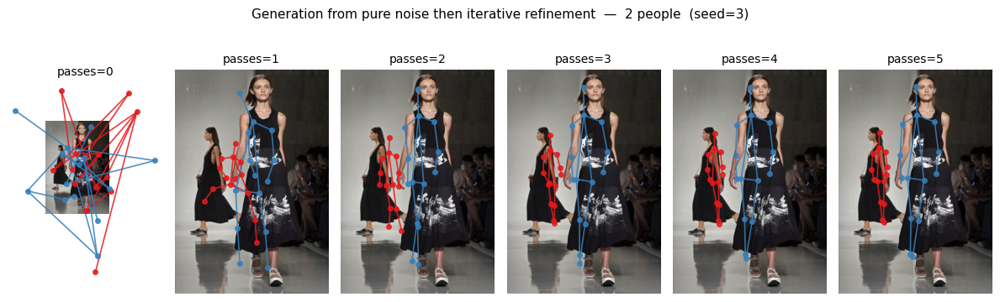

Saved → results/evaluation/figures/f1_noise_generation.png


In [337]:
GEN_PASSES_LIST = [0, 1, 2, 3, 4, 5]
GEN_STEPS       = [20, 15, 10, 5, 3, 1]   # diffusion steps per pass; GEN_STEPS[i] drives snapshots[i+1]
GEN_NOISE_FRACS = [1.0, 0.8, 0.6, 0.4, 0.2, 0.1]
GEN_SEED        = 3

# Build a proper batched dict from the single-sample s_attn
batch_attn = {
    "keypoints":  s_attn["keypoints"].unsqueeze(0).float(),
    "visibility": s_attn["visibility"].unsqueeze(0),
    "image_id":   [s_attn["image_id"]],
    "img_path":   [s_attn["img_path"]],
}

_, graph_gen = module_mp.prepare_batch(batch_attn)
T_full     = module_mp.model.config.num_train_steps
img_wh_gen = graph_gen.img_wh[0].cpu()
N_people   = graph_gen.N

edge_index_d   = graph_gen.edge_index.to(DEVICE)
kpt_type_idx_d = graph_gen.flat_kpt_type_idx.to(DEVICE)
node_batch_d   = graph_gen.node_batch.to(DEVICE)
image_cond_d   = graph_gen.image_cond.to(DEVICE) if graph_gen.image_cond is not None else None
global_cond_d  = graph_gen.global_image_cond.to(DEVICE) if graph_gen.global_image_cond is not None else None

v_full = torch.full((N_people, 14), 2, dtype=torch.long)

# snapshots[0]: pure Gaussian noise in pixel space (no denoising)
torch.manual_seed(GEN_SEED)
x_noise = torch.randn(graph_gen.num_nodes, 2)   # (N*14, 2), canonical space
noise_px = (x_noise + 1) / 2 * img_wh_gen
snapshots = {0: noise_px.view(N_people, 14, 2)}

# snapshots[1]: full denoising from that noise (GEN_STEPS[0] diffusion steps)
gen_canonical = module_mp.model.ddim_sample(
    edge_index=edge_index_d,
    kpt_type_idx=kpt_type_idx_d,
    batch_idx=node_batch_d,
    num_nodes=graph_gen.num_nodes,
    num_inference_steps=GEN_STEPS[0],
    start_t=T_full,
    device=DEVICE,
    x_init=x_noise.to(DEVICE),
    image_cond=image_cond_d,
    global_image_cond=global_cond_d,
)
kpts_px = (gen_canonical.cpu() + 1) / 2 * img_wh_gen
kpts_px = kpts_px.view(N_people, 14, 2)
snapshots[1] = kpts_px.clone()

# snapshots[2..5]: iterative refinement passes
for i, (noise_frac, step) in enumerate(zip(GEN_NOISE_FRACS[1:], GEN_STEPS[1:]), start=2):
    kpts_px = run_refine(
        module_mp, make_refine_batch(s_attn, kpts_px),
        n_steps=step, noise_frac=noise_frac,
    )
    snapshots[i] = kpts_px.clone()

fig, axes = plt.subplots(1, len(GEN_PASSES_LIST), figsize=(2 * len(GEN_PASSES_LIST), 4), squeeze=False)

for col, n_passes in enumerate(GEN_PASSES_LIST):
    ax = axes[0, col]
    ax.imshow(img_attn)
    draw_pose(ax, snapshots[n_passes], v_full, alpha=0.85, lw=1.2, ms=4)
    ax.set_title(f"passes={n_passes}", fontsize=10)
    ax.axis("off")

fig.suptitle(
    f"Generation from pure noise then iterative refinement  —  {N_people} people  "
    f"(seed={GEN_SEED})",
    fontsize=11,
)
plt.tight_layout()
save_path = EVAL_DIR / "figures" / "f1_noise_generation.png"
fig.savefig(save_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved → {save_path}")
